# 48 GB Deep Dive: Linking Decode Speed to `p99` TTFT (`St.WAITING`)

A fast standalone notebook running only the 4 key policies at **`48 GB` HBM (`Exgentic SWE-bench, λ=0.15`)** to show visually how **slow `St.DECODE` inside HBM** (under uncapped `Pack-HBM`) drives the **`p99` `St.WAITING` tail** at the door, and how `B_cap=12` fixes both.

In [1]:
import os, sys
import numpy as np
import matplotlib.pyplot as plt
from concurrent.futures import ProcessPoolExecutor

if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir(os.path.abspath(".."))
sys.path.insert(0, os.getcwd())

from sim.paged_vs_oracle import run_capped_sim

plt.rcParams.update({
    "figure.dpi": 120,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

trace_path = "data/external_traces/exgentic_swebench.jsonl"
n_req, seed, max_time, rate, hbm = 40, 42, 6000.0, 0.15, 48.0

specs = [
    ("Pack (Full LRU)",       "Baseline Full LRU",   {},             "#94a3b8"),
    ("Pack (Paged Oracle)",   "Paged Oracle (JIT)",  {},             "#64748b"),
    ("B_cap=12 + Paged LRU",  "CappedNaivePagedLRU", {"b_cap": 12},  "#f59e0b"),
    ("B_cap=12 + Paged Oracle","CappedPagedOracle",  {"b_cap": 12},  "#2563eb"),
]

tasks = [(lbl, bp, hbm, rate, n_req, seed, max_time, trace_path, kw) for lbl, bp, kw, _ in specs]
res = {}
with ProcessPoolExecutor() as ex:
    for lbl, s in ex.map(run_capped_sim, tasks):
        res[lbl] = s

print(f"{'Policy (48 GB)':26s} | {'ActiveB':7s} | {'Decode/req':10s} | {'Prefill/req':11s} | {'Wait/req':9s} | {'Top1% TTFT':10s} | {'MeanE2E':9s}")
print("-" * 98)
for lbl, _, _, _ in specs:
    s = res[lbl]
    ss, rs, td = s["state_seconds"], s["residency_seconds"], s["ttft_decomp"]
    n = float(s["total_requests"])
    act_b = rs["active_compute"] / max(1e-9, rs["active_wall"])
    dec_r = ss["DECODE"] / n
    pre_r = ss["PREFILL"] / n
    wai_r = ss["WAITING"] / n
    top1 = td["p99_wait"] + td["p99_stall"] + td["p99_prefill"]
    print(f"{lbl:26s} | {act_b:7.2f} | {dec_r:8.1f} s | {pre_r:9.1f} s | {wai_r:7.1f} s | {top1:8.1f} s | {s['mean_e2e_s']:7.1f} s")

Policy (48 GB)             | ActiveB | Decode/req | Prefill/req | Wait/req  | Top1% TTFT | MeanE2E  
--------------------------------------------------------------------------------------------------
Pack (Full LRU)            |    9.85 |    916.3 s |       0.0 s |   467.1 s |    470.7 s |  1734.1 s
Pack (Paged Oracle)        |    9.73 |    909.1 s |       0.0 s |   462.7 s |    482.2 s |  1725.3 s
B_cap=12 + Paged LRU       |    8.32 |    801.5 s |       0.0 s |   527.9 s |    134.3 s |  1677.7 s
B_cap=12 + Paged Oracle    |    8.32 |    798.4 s |       0.0 s |   528.1 s |    152.3 s |  1675.2 s


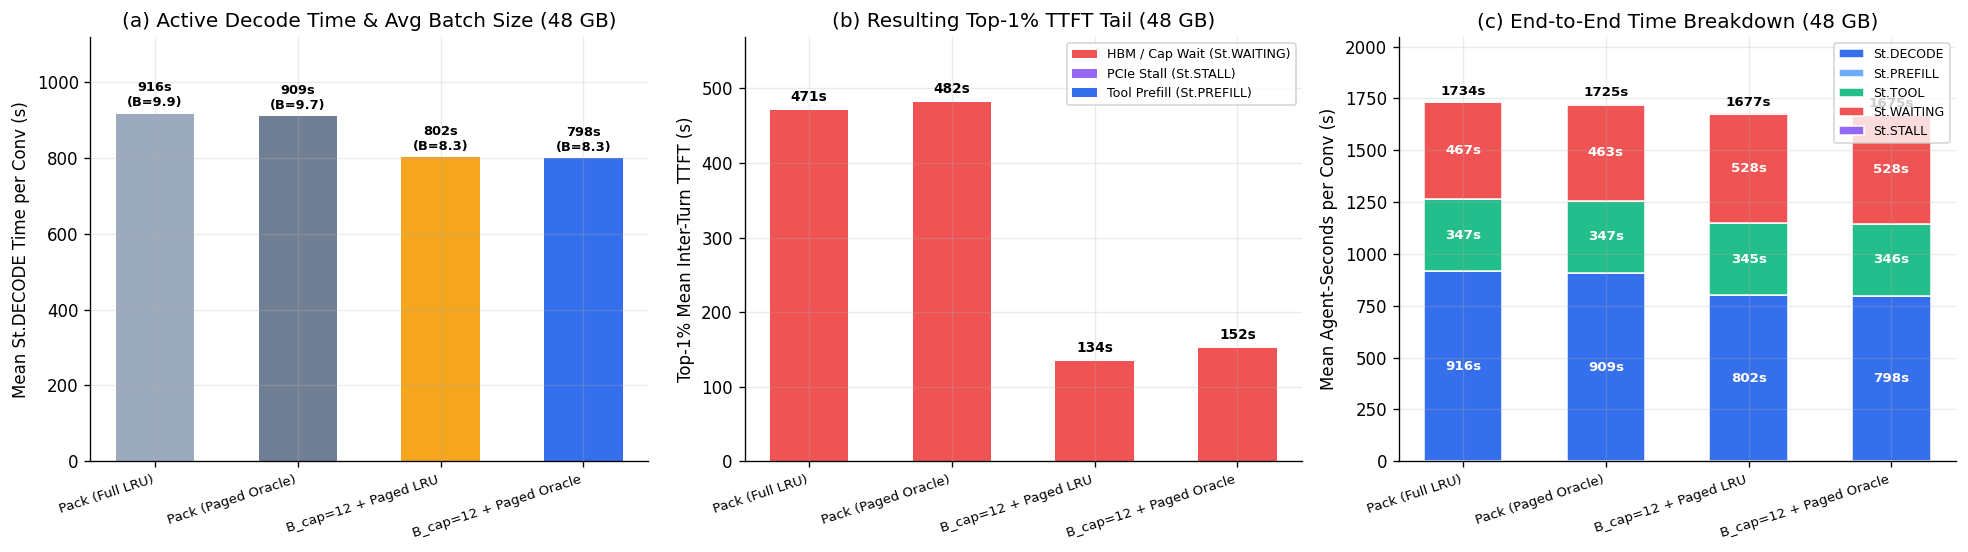

In [2]:
fig, axes = plt.subplots(1, 3, figsize=(16.5, 4.7))
lbls = [x[0] for x in specs]
cols = [x[3] for x in specs]
xb = np.arange(len(lbls))

# (a) Active Batch Size vs Mean St.DECODE Time per Request
dec_vals = [res[l]["state_seconds"]["DECODE"] / res[l]["total_requests"] for l in lbls]
act_vals = [res[l]["residency_seconds"]["active_compute"] / max(1e-9, res[l]["residency_seconds"]["active_wall"]) for l in lbls]

bars = axes[0].bar(xb, dec_vals, 0.55, color=cols, alpha=0.92)
for xi, dv, av in zip(xb, dec_vals, act_vals):
    axes[0].text(xi, dv + 12, f"{dv:.0f}s\n(B={av:.1f})", ha="center", va="bottom", fontsize=7.8, fontweight="bold")
axes[0].set_xticks(xb); axes[0].set_xticklabels(lbls, fontsize=8, rotation=18, ha="right")
axes[0].set_ylabel("Mean St.DECODE Time per Conv (s)")
axes[0].set_title("(a) Active Decode Time & Avg Batch Size (48 GB)")
axes[0].set_ylim(0, max(dec_vals) * 1.22)

# (b) Top-1% (p99+) TTFT Breakdown
pw = np.array([res[l]["ttft_decomp"]["p99_wait"] for l in lbls])
ps = np.array([res[l]["ttft_decomp"]["p99_stall"] for l in lbls])
pp = np.array([res[l]["ttft_decomp"]["p99_prefill"] for l in lbls])
axes[1].bar(xb, pw, 0.55, label="HBM / Cap Wait (St.WAITING)", color="#ef4444", alpha=0.92)
axes[1].bar(xb, ps, 0.55, bottom=pw, label="PCIe Stall (St.STALL)", color="#8b5cf6", alpha=0.92)
axes[1].bar(xb, pp, 0.55, bottom=pw+ps, label="Tool Prefill (St.PREFILL)", color="#2563eb", alpha=0.92)
for xi, tot in zip(xb, pw + ps + pp):
    axes[1].text(xi, tot + 8, f"{tot:.0f}s", ha="center", va="bottom", fontsize=8.2, fontweight="bold")
axes[1].set_xticks(xb); axes[1].set_xticklabels(lbls, fontsize=8, rotation=18, ha="right")
axes[1].set_ylabel("Top-1% Mean Inter-Turn TTFT (s)")
axes[1].set_title("(b) Resulting Top-1% TTFT Tail (48 GB)")
axes[1].set_ylim(0, max(pw + ps + pp) * 1.18)
axes[1].legend(fontsize=7.6, loc="upper right")

# (c) Full MeanE2E Time Breakdown per Conversation
dec_a = np.array(dec_vals)
pre_a = np.array([res[l]["state_seconds"]["PREFILL"] / res[l]["total_requests"] for l in lbls])
too_a = np.array([res[l]["state_seconds"]["TOOL"] / res[l]["total_requests"] for l in lbls])
wai_a = np.array([res[l]["state_seconds"]["WAITING"] / res[l]["total_requests"] for l in lbls])
sta_a = np.array([res[l]["state_seconds"]["STALL"] / res[l]["total_requests"] for l in lbls])

bot = np.zeros(len(lbls))
for name, arr, c in [
    ("St.DECODE", dec_a, "#2563eb"),
    ("St.PREFILL", pre_a, "#60a5fa"),
    ("St.TOOL", too_a, "#10b981"),
    ("St.WAITING", wai_a, "#ef4444"),
    ("St.STALL", sta_a, "#8b5cf6"),
]:
    axes[2].bar(xb, arr, 0.55, bottom=bot, label=name, color=c, alpha=0.92, edgecolor="white")
    for xi, v, b in zip(xb, arr, bot):
        if v >= 120:
            axes[2].text(xi, b + v / 2.0, f"{v:.0f}s", ha="center", va="center", color="white", fontsize=8, fontweight="bold")
    bot += arr
for xi, tot in zip(xb, bot):
    axes[2].text(xi, tot + 20, f"{tot:.0f}s", ha="center", va="bottom", fontsize=8, fontweight="bold")
axes[2].set_xticks(xb); axes[2].set_xticklabels(lbls, fontsize=8, rotation=18, ha="right")
axes[2].set_ylabel("Mean Agent-Seconds per Conv (s)")
axes[2].set_title("(c) End-to-End Time Breakdown (48 GB)")
axes[2].set_ylim(0, max(bot) * 1.18)
axes[2].legend(fontsize=7.5, loc="upper right")

plt.tight_layout()
plt.show()